# EDA

In [82]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Load the dataset
train_data = pd.read_csv('train_data.csv')
valid_data = pd.read_csv('valid_data.csv')
# Display basic information about the dataset
train_data_info = train_data.info()
valid_info = valid_data.info()
train_data_head = train_data.head()


valid_head = valid_data.head()

train_data_info, valid_info, train_data_head, valid_head

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55712 entries, 0 to 55711
Data columns (total 38 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Unnamed: 0                                55712 non-null  int64  
 1   days_90_queries                           54275 non-null  float64
 2   flag_zpexp                                55712 non-null  int64  
 3   ageolddate_f7                             55259 non-null  float64
 4   f41_my                                    23777 non-null  float64
 5   age2                                      55712 non-null  float64
 6   f39_my                                    19307 non-null  float64
 7   active_crd_amount_to_limit                36437 non-null  float64
 8   sumlastvalue_7_f50                        33036 non-null  float64
 9   avg_active_credit_limit                   38207 non-null  float64
 10  total_amount                      

(None,
 None,
    Unnamed: 0  days_90_queries  flag_zpexp  ageolddate_f7  f41_my  age2  \
 0           0              4.0           0           26.0     NaN  25.0   
 1           1              2.0           0          101.0     NaN  31.0   
 2           2             11.0           0           46.0     NaN  22.0   
 3           3              4.0           0          126.0     NaN  45.0   
 4           4              4.0           0          126.0     NaN  45.0   
 
    f39_my  active_crd_amount_to_limit  sumlastvalue_7_f50  \
 0    12.0                         NaN             6017.76   
 1     NaN                    0.654416                 NaN   
 2     NaN                    0.608811                 NaN   
 3     NaN                    0.761899                 NaN   
 4     NaN                    0.761899                 NaN   
 
    avg_active_credit_limit  ...  agelifelastterm_f29  cntstartcntr_3_f75  \
 0                      NaN  ...                 15.0                 0.0   


In [83]:
# Check for missing values in each column
missing_values = train_data.isnull().sum()
valid_missing_values = valid_data.isnull().sum()
train_data_describe = train_data.describe()
valid_data_describe = valid_data.describe()

missing_values, valid_missing_values, train_data_describe, valid_data_describe

(Unnamed: 0                                      0
 days_90_queries                              1437
 flag_zpexp                                      0
 ageolddate_f7                                 453
 f41_my                                      31935
 age2                                            0
 f39_my                                      36405
 active_crd_amount_to_limit                  19275
 sumlastvalue_7_f50                          22676
 avg_active_credit_limit                     17505
 total_amount                                 3461
 amount_of_last_term_contr                    8546
 avgcontractlife                              7265
 sm_plus_3_months_rt                         13807
 ageoldexsdate_f5                             1759
 total_crd_cnt                                 452
 gender                                        453
 inst_crd_cnt                                11750
 avg_active_amount                           12250
 max_overdue_cr_card           

In [85]:
# Calculate the percentage of missing values in each column for training and validation data
missing_values_train = train_data.isnull().sum() / len(train_data) * 100
missing_values_valid = valid_data.isnull().sum() / len(valid_data) * 100

missing_values_train = missing_values_train[missing_values_train > 0].sort_values(ascending=False)
missing_values_valid = missing_values_valid[missing_values_valid > 0].sort_values(ascending=False)
missing_values_train, missing_values_valid

(final_resincome                             69.645678
 f39_my                                      65.344989
 f41_my                                      57.321582
 f38_my                                      50.807725
 sumlastvalue_7_f50                          40.702183
 active_crd_amount_to_limit                  34.597573
 avg_active_credit_limit                     31.420520
 max_active_crd_res_amount_to_limit          31.420520
 sm_plus_3_months_rt                         24.782812
 max_del_history                             24.280227
 inst_credit_cnt                             22.652211
 avg_active_amount                           21.988082
 active_number_of_outstanding_instalments    21.986287
 inst_crd_cnt                                21.090609
 total_credit_limit                          16.303489
 amount_of_last_term_contr                   15.339604
 avgcontractlife                             13.040279
 agelifelastterm_f29                          8.256749
 f8       

# Data Preprocessing, Feature Selection

In [89]:
train_data.drop(columns=['Unnamed: 0'], inplace=True)
valid_data.drop(columns=['Unnamed: 0'], inplace=True)

In [91]:
# Check missing values in both datasets
train_missing = train_data.isnull().sum() / len(train_data) * 100
valid_missing = valid_data.isnull().sum() / len(valid_data) * 100

# Identify columns with more than 40% missing values in BOTH datasets
columns_to_drop = set(train_missing[train_missing > 12].index) & set(valid_missing[valid_missing > 12].index)

# Drop these columns from both datasets
train_data = train_data.drop(columns=columns_to_drop)
valid_data = valid_data.drop(columns=columns_to_drop)

train_data.info(), valid_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55712 entries, 0 to 55711
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   days_90_queries          54275 non-null  float64
 1   flag_zpexp               55712 non-null  int64  
 2   ageolddate_f7            55259 non-null  float64
 3   age2                     55712 non-null  float64
 4   total_amount             52251 non-null  float64
 5   avgcontractlife          48447 non-null  float64
 6   ageoldexsdate_f5         53953 non-null  float64
 7   total_crd_cnt            55260 non-null  float64
 8   gender                   55259 non-null  float64
 9   avg_active_amount        43462 non-null  float64
 10  max_overdue_cr_card      54310 non-null  float64
 11  overdue_credit_contract  54310 non-null  float64
 12  total_credit_limit       46629 non-null  float64
 13  max_del_history          42185 non-null  float64
 14  cnt_overdue_0_f151    

(None, None)

In [93]:
# Calculate the percentage of missing values in each column for training and validation data
missing_values_train = train_data.isnull().sum() / len(train_data) * 100
missing_values_valid = valid_data.isnull().sum() / len(valid_data) * 100

missing_values_train = missing_values_train[missing_values_train > 0].sort_values(ascending=False)
missing_values_valid = missing_values_valid[missing_values_valid > 0].sort_values(ascending=False)
missing_values_train, missing_values_valid

(max_del_history            24.280227
 avg_active_amount          21.988082
 total_credit_limit         16.303489
 avgcontractlife            13.040279
 agelifelastterm_f29         8.256749
 f8                          7.942634
 total_amount                6.212306
 ageoldexsdate_f5            3.157309
 days_90_queries             2.579337
 max_overdue_cr_card         2.516513
 overdue_credit_contract     2.516513
 value_cr_card_contract      2.516513
 cnt_overdue_0_f151          2.460870
 closedel_6                  0.822085
 closedel_12_f95             0.822085
 gender                      0.813110
 ageolddate_f7               0.813110
 total_crd_cnt               0.811315
 credit_closed_cnt           0.811315
 cntstartcntr_3_f75          0.811315
 f156                        0.777211
 dtype: float64,
 avg_active_amount          11.590237
 max_del_history            11.390533
 total_credit_limit         11.139053
 avgcontractlife            10.288462
 agelifelastterm_f29         5.55

In [95]:
# Columns with less than 5% missing values in train and valid data
cols_train_to_drop = missing_values_train[missing_values_train < 5].index
cols_valid_to_drop = missing_values_valid[missing_values_valid < 5].index

# Drop rows with missing values in columns with less than 5% missing data
train_data = train_data.dropna(subset=cols_train_to_drop)
valid_data = valid_data.dropna(subset=cols_valid_to_drop)

# Show the shapes of the cleaned datasets
print(f"Train data shape after cleaning: {train_data.shape}")
print(f"Validation data shape after cleaning: {valid_data.shape}")

Train data shape after cleaning: (52282, 24)
Validation data shape after cleaning: (12667, 24)


we delete the 'max_del_history', 'avg_active_amount' because of high percentage missing values

In [98]:
train_data.drop(columns=['max_del_history', 'avg_active_amount'], inplace=True)
valid_data.drop(columns=['max_del_history', 'avg_active_amount'], inplace=True)

In [100]:
# Check for duplicate rows in both datasets
train_duplicates = train_data.duplicated().sum()
valid_duplicates = valid_data.duplicated().sum()

# Remove duplicates if any
train_data = train_data.drop_duplicates()
valid_data = valid_data.drop_duplicates()

# Get new shapes after duplicate removal
train_shape_after_dup_removal = train_data.shape
valid_shape_after_dup_removal = valid_data.shape

train_duplicates, valid_duplicates, train_shape_after_dup_removal, valid_shape_after_dup_removal

(12116, 2537, (40166, 22), (10130, 22))

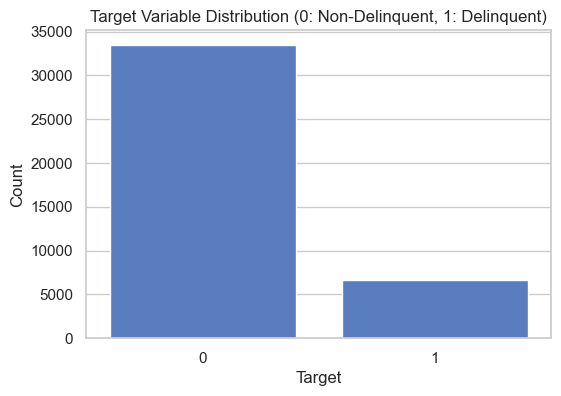

target
0    83.349101
1    16.650899
Name: proportion, dtype: float64

In [102]:
# Visualize the target variable distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=train_data)
plt.title('Target Variable Distribution (0: Non-Delinquent, 1: Delinquent)')
plt.ylabel('Count')
plt.xlabel('Target')
plt.show()

# Check class distribution of the target variable
target_distribution = train_data['target'].value_counts(normalize=True) * 100

# Display the target distribution
target_distribution

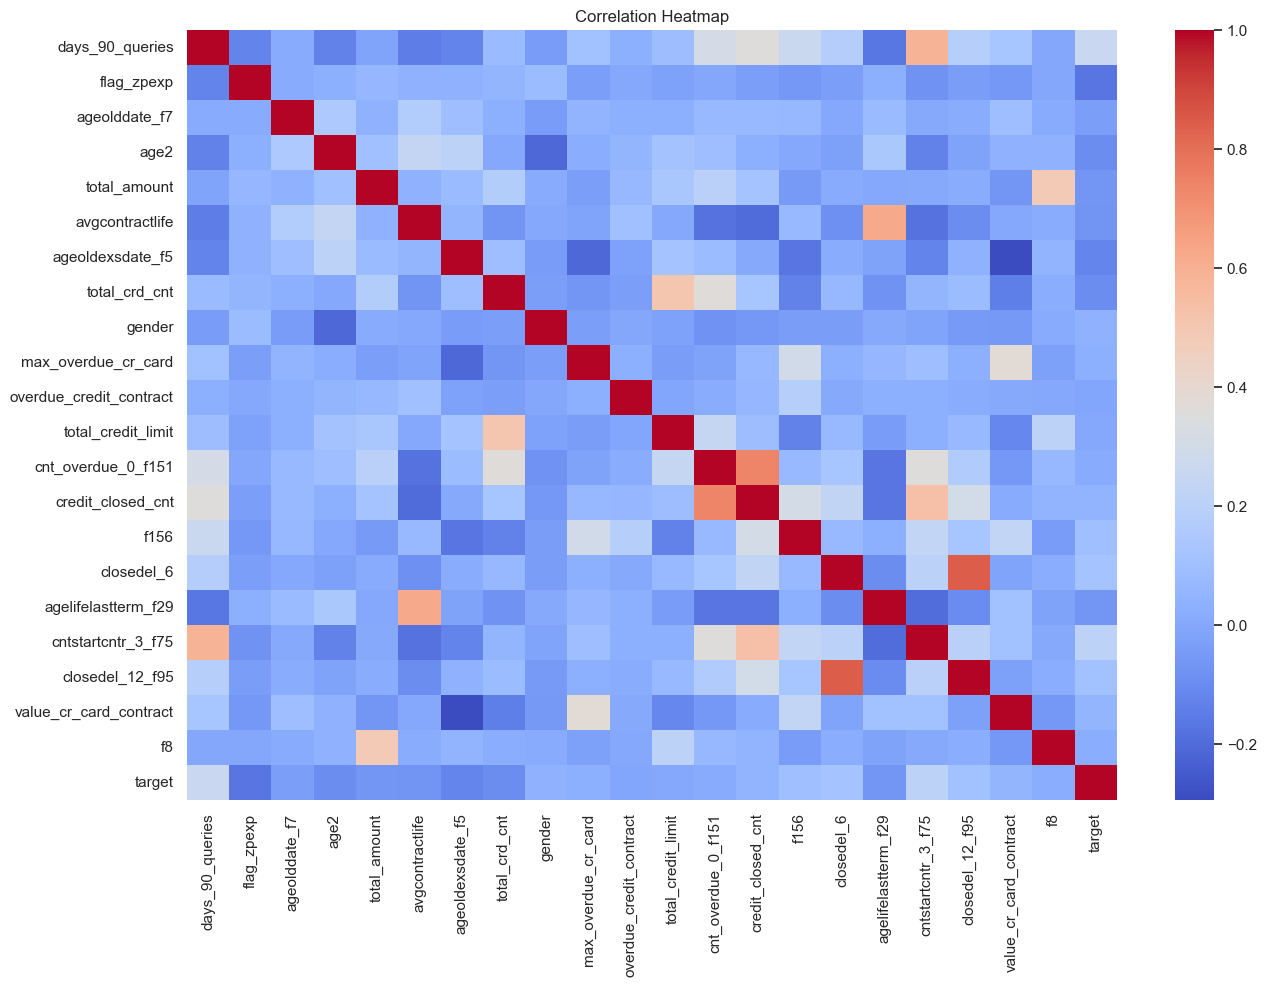

target                     1.000000
days_90_queries            0.257243
cntstartcntr_3_f75         0.206771
flag_zpexp                 0.170154
ageoldexsdate_f5           0.117422
closedel_6                 0.117134
closedel_12_f95            0.108880
f156                       0.098769
total_crd_cnt              0.096565
age2                       0.095583
avgcontractlife            0.070518
agelifelastterm_f29        0.065495
total_amount               0.062264
value_cr_card_contract     0.052302
credit_closed_cnt          0.045607
gender                     0.043844
ageolddate_f7              0.034422
max_overdue_cr_card        0.028174
f8                         0.021131
cnt_overdue_0_f151         0.012143
overdue_credit_contract    0.009354
total_credit_limit         0.001415
Name: target, dtype: float64

In [104]:
# Set plot style
sns.set(style="whitegrid", palette="muted")

# Correlation heatmap for features
correlation_matrix = train_data.corr()
plt.figure(figsize=(15, 10))
sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", cbar=True)
plt.title("Correlation Heatmap")
plt.show()

# Top correlations with target
correlation_with_target = correlation_matrix["target"].abs().sort_values(ascending=False)
correlation_with_target

'overdue_credit_contract', "total_credit_limit" and 'cnt_overdue_0_f151' have the lowest correlation with target, so we delete them.

In [106]:
train_data.drop(columns=['overdue_credit_contract', 'total_credit_limit', 'cnt_overdue_0_f151'], inplace=True)
valid_data.drop(columns=['overdue_credit_contract', 'total_credit_limit', 'cnt_overdue_0_f151'], inplace=True)

In [108]:
correlation_value = train_data.corr().loc['closedel_6', 'closedel_12_f95']
print(f"Correlation between closedel_6 and closedel_12_f95: {correlation_value}")

Correlation between closedel_6 and closedel_12_f95: 0.8472484665694232


closedel_6 and closedel_12_f95 have a strong correlation of 0.845, indicating redundancy. Consider keeping closedel_12_f95 as it may capture a longer time frame, offering more comprehensive information.

In [112]:
train_data.drop(columns=['closedel_6'], inplace=True)
valid_data.drop(columns=['closedel_6'], inplace=True)

ageolddate_f7-Age of the oldest contract, agelifelastterm_f29-Age at last contract term, f8-Average amount of the minimum payment for active contracts are irrelevant data. So we remove them

In [115]:
train_data.drop(columns=['ageolddate_f7', 'agelifelastterm_f29', 'f8'], inplace=True)
valid_data.drop(columns=['ageolddate_f7', 'agelifelastterm_f29', 'f8'], inplace=True)

We drop "value_cr_card_contract" because it showed low importance in models training

In [155]:
train_data.drop(columns=['value_cr_card_contract'], inplace=True)
valid_data.drop(columns=['value_cr_card_contract'], inplace=True)

KeyError: "['value_cr_card_contract'] not found in axis"

# Feature Engineering

In [ ]:
if 'age2' in train_data.columns:
    train_data['age2_binned'] = pd.cut(train_data['age2'], bins=[0, 25, 45, 100], labels=['Young', 'Adult', 'Senior'])
    valid_data['age2_binned'] = pd.cut(valid_data['age2'], bins=[0, 25, 45, 100], labels=['Young', 'Adult', 'Senior'])

train_data = train_data.drop(columns=['age2'])
valid_data = valid_data.drop(columns=['age2'])

# Verify the modified dataset
print(train_data.head())
print(valid_data.head())

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Initialize the LabelEncoder
le = LabelEncoder()

# Apply Label Encoding to 'age2_binned' in training data
train_data['age2_binned'] = le.fit_transform(train_data['age2_binned'])

# Apply the same transformation to 'age2_binned' in validation data
valid_data['age2_binned'] = le.transform(valid_data['age2_binned'])

# Verify the transformation by displaying the encoded values
print(train_data[['age2_binned']].head())
print(valid_data[['age2_binned']].head())

# Data Visualization 

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Identify numerical columns (excluding target variable if it exists)
numerical_features = train_data.select_dtypes(include=['float64', 'int64']).columns.tolist()
numerical_features.remove('target')  # Ensure target is removed safely

# Set plot size
plt.figure(figsize=(20, 15))

# Generate box plots for each numerical feature
for i, feature in enumerate(numerical_features):
    plt.subplot(len(numerical_features) // 3 + 1, 3, i + 1)
    sns.boxplot(x=train_data[feature])
    plt.title(feature)

plt.tight_layout()
plt.show()

In [ ]:
# Plot histograms for numerical features
plt.figure(figsize=(20, 15))
for i, feature in enumerate(numerical_features):
    plt.subplot(len(numerical_features) // 3 + 1, 3, i + 1)
    sns.histplot(train_data[feature], bins=20, kde=True)
    plt.title(feature)

plt.tight_layout()
plt.show()

In [161]:
import pandas as pd
from sklearn.impute import SimpleImputer

# Separate numerical and categorical columns
numerical_columns = train_data.select_dtypes(include=['float64', 'int64']).columns.tolist()

# Initialize imputer for numerical and categorical columns
numerical_imputer = SimpleImputer(strategy='median')

# Apply imputation to numerical columns
train_data[numerical_columns] = numerical_imputer.fit_transform(train_data[numerical_columns])
valid_data[numerical_columns] = numerical_imputer.transform(valid_data[numerical_columns])

# Verify that there are no more missing values
train_missing_after_imputation = train_data.isnull().sum().sum()
valid_missing_after_imputation = valid_data.isnull().sum().sum()

train_missing_after_imputation, valid_missing_after_imputation

(0, 0)

In [163]:
# Identify numerical features excluding 'flag_zpexp' and 'gender'
numerical_features_filtered = [col for col in numerical_features if col not in ['flag_zpexp', 'gender', 'target']]

# Define function for capping outliers based on percentiles
def cap_outliers(df, columns, lower_percentile=0.01, upper_percentile=0.99):
    lower_bounds = df[columns].quantile(lower_percentile)
    upper_bounds = df[columns].quantile(upper_percentile)

    # Use .loc to apply capping
    df.loc[:, columns] = df[columns].clip(lower=lower_bounds, upper=upper_bounds, axis=1)

    # Convert integer columns back to int (after rounding)
    int_columns = df[columns].select_dtypes(include=['int64', 'int32']).columns
    df.loc[:, int_columns] = df[int_columns].round().astype('int64')  

    return df.copy()  # Return a copy to avoid SettingWithCopyWarning

# Apply capping on train dataset only (to prevent data leakage)
train_data = cap_outliers(train_data, numerical_features_filtered)

train_data.shape

(40166, 14)

In [165]:
from sklearn.preprocessing import StandardScaler

# Initialize the standard scaler
scaler = StandardScaler()

# Identify numerical columns (excluding target variable)
numerical_features = [col for col in train_data.columns if col != 'target']

# Apply standardization to numerical features
train_data[numerical_features] = scaler.fit_transform(train_data[numerical_features])
valid_data[numerical_features] = scaler.transform(valid_data[numerical_features])

## Model training, GridSearchCV, Evaluation

In [168]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.linear_model import LogisticRegression

X_train = train_data.drop(columns=["target"])
y_train = train_data["target"]
X_valid = valid_data.drop(columns=["target"])
y_valid = valid_data["target"]

# Define Logistic Regression model
log_reg = LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=500)

# Define hyperparameter grid
param_grid_log = {
    "C": [0.01, 0.1, 1, 10, 100],  # Regularization strength
    "penalty": ["l1", "l2"]  # Regularization type
}

# Perform Grid Search
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search_log = GridSearchCV(log_reg, param_grid_log, cv=cv_strategy, scoring="roc_auc", n_jobs=-1, verbose=1)
grid_search_log.fit(X_train, y_train)

# Best model
best_log_reg = grid_search_log.best_estimator_
print("Best Parameters for Logistic Regression:", grid_search_log.best_params_)

# Evaluate model
y_pred = best_log_reg.predict(X_valid)
y_proba = best_log_reg.predict_proba(X_valid)[:, 1]

print("\nClassification Report for Logistic Regression:")
print(classification_report(y_valid, y_pred))

print("\nAUC-ROC Score:", roc_auc_score(y_valid, y_proba))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters for Logistic Regression: {'C': 0.1, 'penalty': 'l1'}

Classification Report for Logistic Regression:
              precision    recall  f1-score   support

         0.0       0.97      0.72      0.82      9265
         1.0       0.20      0.74      0.31       865

    accuracy                           0.72     10130
   macro avg       0.58      0.73      0.57     10130
weighted avg       0.90      0.72      0.78     10130


AUC-ROC Score: 0.7970773218870196


In [169]:
# Import necessary libraries
from sklearn.tree import DecisionTreeClassifier

# Define Decision Tree model
decision_tree = DecisionTreeClassifier(class_weight="balanced", random_state=42)

# Define hyperparameter grid
param_grid_dt = {
    "max_depth": [5, 10, 20, None],  # Tree depth
    "min_samples_split": [2, 5, 10],  # Minimum samples to split a node
    "min_samples_leaf": [1, 2, 4]  # Minimum samples per leaf
}

# Perform Grid Search
grid_search_dt = GridSearchCV(decision_tree, param_grid_dt, cv=cv_strategy, scoring="roc_auc", n_jobs=-1, verbose=1)
grid_search_dt.fit(X_train, y_train)

# Best model
best_dt = grid_search_dt.best_estimator_
print("Best Parameters for Decision Tree:", grid_search_dt.best_params_)

# Evaluate model
y_pred = best_dt.predict(X_valid)
y_proba = best_dt.predict_proba(X_valid)[:, 1]

print("\nClassification Report for Decision Tree:")
print(classification_report(y_valid, y_pred))

print("\nAUC-ROC Score:", roc_auc_score(y_valid, y_proba))
# Get feature importance
feature_importance = best_dt.feature_importances_
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importance
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print(importance_df)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best Parameters for Decision Tree: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2}

Classification Report for Decision Tree:
              precision    recall  f1-score   support

         0.0       0.97      0.65      0.78      9265
         1.0       0.17      0.77      0.28       865

    accuracy                           0.66     10130
   macro avg       0.57      0.71      0.53     10130
weighted avg       0.90      0.66      0.73     10130


AUC-ROC Score: 0.7677321887019644
                Feature  Importance
0       days_90_queries    0.512642
1            flag_zpexp    0.260303
5         total_crd_cnt    0.095897
10   cntstartcntr_3_f75    0.040692
7   max_overdue_cr_card    0.032262
4      ageoldexsdate_f5    0.021913
11      closedel_12_f95    0.020582
3       avgcontractlife    0.007133
8     credit_closed_cnt    0.004267
2          total_amount    0.001790
9                  f156    0.001430
12 

In [170]:
# Import necessary libraries
from sklearn.ensemble import RandomForestClassifier

# Define Random Forest model
random_forest = RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1)

# Define hyperparameter grid
param_grid_rf = {
    "n_estimators": [100, 200],  # Number of trees
    "max_depth": [10, 20],  # Tree depth
    "min_samples_split": [2, 5, 10],  # Minimum samples to split a node
}

# Perform Grid Search
grid_search_rf = GridSearchCV(random_forest, param_grid_rf, cv=5, scoring="roc_auc", n_jobs=-1, verbose=1)
grid_search_rf.fit(X_train, y_train)

# Best model
best_rf = grid_search_rf.best_estimator_
print("Best Parameters for Random Forest:", grid_search_rf.best_params_)

# Evaluate model
y_pred = best_rf.predict(X_valid)
y_proba = best_rf.predict_proba(X_valid)[:, 1]

print("\nClassification Report for Random Forest:")
print(classification_report(y_valid, y_pred))

print("\nAUC-ROC Score:", roc_auc_score(y_valid, y_proba))

# Get feature importance
feature_importance = best_rf.feature_importances_
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importance
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print(importance_df)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters for Random Forest: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 200}

Classification Report for Random Forest:
              precision    recall  f1-score   support

         0.0       0.97      0.73      0.83      9265
         1.0       0.20      0.74      0.32       865

    accuracy                           0.73     10130
   macro avg       0.58      0.73      0.57     10130
weighted avg       0.90      0.73      0.79     10130


AUC-ROC Score: 0.8132410807033744
                Feature  Importance
0       days_90_queries    0.236856
1            flag_zpexp    0.159070
10   cntstartcntr_3_f75    0.107127
2          total_amount    0.071698
3       avgcontractlife    0.066170
5         total_crd_cnt    0.064532
4      ageoldexsdate_f5    0.064470
11      closedel_12_f95    0.056529
7   max_overdue_cr_card    0.054980
9                  f156    0.042946
8     credit_closed_cnt    0.038837
12  

In [171]:
from xgboost import XGBClassifier

# Define XGBoost model
xgb = XGBClassifier(scale_pos_weight=y_train.value_counts()[0] / y_train.value_counts()[1], eval_metric="logloss", random_state=42)

# Define hyperparameter grid
param_grid_xgb = {
    "n_estimators": [100, 200],  # Number of boosting rounds
    "max_depth": [3, 6],  # Depth of trees
    "learning_rate": [0.05, 0.4],  # Step size shrinkage
    "subsample": [0.8, 1],  # Percentage of samples used per tree]
}

# Perform Grid Search
grid_search_xgb = GridSearchCV(xgb, param_grid_xgb, cv=cv_strategy, scoring="roc_auc", n_jobs=-1, verbose=1)
grid_search_xgb.fit(X_train, y_train)

# Best model
best_xgb = grid_search_xgb.best_estimator_
print("Best Parameters for XGBoost:", grid_search_xgb.best_params_)

# Evaluate model
y_pred = best_xgb.predict(X_valid)
y_proba = best_xgb.predict_proba(X_valid)[:, 1]

print("\nClassification Report for XGBoost:")
print(classification_report(y_valid, y_pred))

print("\nAUC-ROC Score:", roc_auc_score(y_valid, y_proba))
# Get feature importance
feature_importance =best_xgb.feature_importances_
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importance
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print(importance_df)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Parameters for XGBoost: {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}

Classification Report for XGBoost:
              precision    recall  f1-score   support

         0.0       0.97      0.73      0.83      9265
         1.0       0.20      0.75      0.32       865

    accuracy                           0.73     10130
   macro avg       0.59      0.74      0.58     10130
weighted avg       0.90      0.73      0.79     10130


AUC-ROC Score: 0.8177597958629811
                Feature  Importance
1            flag_zpexp    0.488886
0       days_90_queries    0.120969
5         total_crd_cnt    0.054339
11      closedel_12_f95    0.044935
6                gender    0.042730
10   cntstartcntr_3_f75    0.042137
12          age2_binned    0.038312
9                  f156    0.034264
7   max_overdue_cr_card    0.029688
4      ageoldexsdate_f5    0.028702
2          total_amount    0.026555
8

In [172]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Define AdaBoost model (using Decision Tree as base estimator)
adaboost = AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced'), algorithm='SAMME')

# Define hyperparameter grid
param_grid_ada = {
    "n_estimators": [100, 200],  # Number of boosting rounds
    "learning_rate": [0.01, 0.05, 0.1, 0.2],  # Step size
    'estimator__max_depth': [3, 5],  # Base decision tree max depth tuning
}

# Perform Grid Search
grid_search_ada = GridSearchCV(adaboost, param_grid_ada, cv=cv_strategy, scoring="roc_auc", n_jobs=-1, verbose=1)
grid_search_ada.fit(X_train, y_train)

# Best model
best_ada = grid_search_ada.best_estimator_
print("Best Parameters for AdaBoost:", grid_search_ada.best_params_)

# Evaluate model
y_pred = best_ada.predict(X_valid)
y_proba = best_ada.predict_proba(X_valid)[:, 1]

print("\nClassification Report for AdaBoost:")
print(classification_report(y_valid, y_pred))

print("\nAUC-ROC Score:", roc_auc_score(y_valid, y_proba))

# Get feature importance
feature_importance = best_ada.feature_importances_
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importance
}).sort_values(by='Importance', ascending=False)

# Display the feature importance
print(importance_df)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Parameters for AdaBoost: {'estimator__max_depth': 5, 'learning_rate': 0.05, 'n_estimators': 200}

Classification Report for AdaBoost:
              precision    recall  f1-score   support

         0.0       0.97      0.63      0.76      9265
         1.0       0.17      0.81      0.28       865

    accuracy                           0.64     10130
   macro avg       0.57      0.72      0.52     10130
weighted avg       0.90      0.64      0.72     10130


AUC-ROC Score: 0.7804727219412981
                Feature  Importance
0       days_90_queries    0.408429
1            flag_zpexp    0.326008
5         total_crd_cnt    0.078721
10   cntstartcntr_3_f75    0.043619
11      closedel_12_f95    0.043437
12          age2_binned    0.023517
7   max_overdue_cr_card    0.021354
9                  f156    0.016233
2          total_amount    0.014847
4      ageoldexsdate_f5    0.013919
8     credit_closed_cnt    0.005966
6     

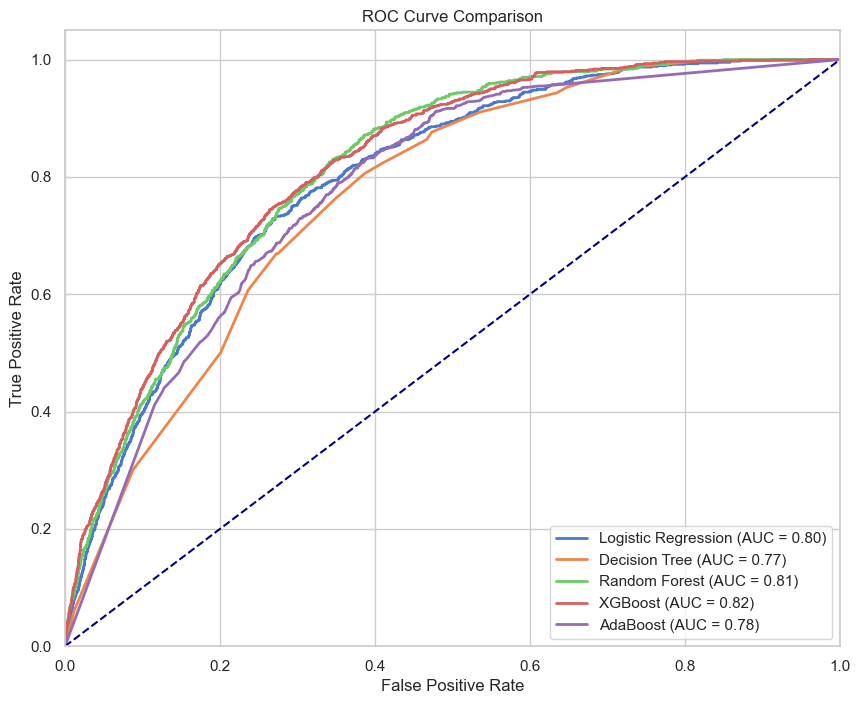

In [179]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Define the models and their names
models = [best_log_reg, best_dt, best_rf, best_xgb, best_ada]
model_names = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'AdaBoost']

# Create the plot
plt.figure(figsize=(10, 8))

# Iterate through models to plot the ROC curve for each
for model, name in zip(models, model_names):
    # Get probabilities for the positive class (delinquent)
    y_proba = model.predict_proba(X_valid)[:, 1]
    
    # Compute ROC curve
    fpr, tpr, _ = roc_curve(y_valid, y_proba)
    roc_auc = auc(fpr, tpr)
    
    # Plot the ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.2f})')

# Add diagonal line for random classifier
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')  

# Set plot limits
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

# Set labels and title
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')

# Show legend and grid
plt.legend(loc='lower right')
plt.grid(True)

# Display the plot
plt.show()
